Imports and loading

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib   # to save the trained models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix,
)

In [17]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv")["Class"]
y_test = pd.read_csv("../data/processed/y_test.csv")["Class"]

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (226980, 30) | Test: (56746, 30)


In [18]:
def evaluate_model(name, model, X_test, y_test):
    """Evaluate a trained model on the test set and return the scores as a dictionary."""

    y_pred = model.predict(X_test)                    # predicted class: 0 or 1
    y_prob = model.predict_proba(X_test)[:, 1]        # predicted probability of fraud

    # Breakdown of correct and wrong predictions
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    return {
        "Model": name,
        "Precision": round(precision_score(y_test, y_pred), 3),
        "Recall": round(recall_score(y_test, y_pred), 3),
        "F1": round(f1_score(y_test, y_pred), 3),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 3),
        "Frauds caught (TP)": tp,
        "Frauds missed (FN)": fn,
        "False alarms (FP)": fp,
    }

# Results from all models will be collected here
results = []

Model 1, Logistic Regression

In [19]:
# class_weight="balanced" makes fraud mistakes cost more during training
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)

# Train the model on the training data
log_reg.fit(X_train, y_train)

# Evaluate on the test set and save the scores
results.append(evaluate_model("Logistic Regression", log_reg, X_test, y_test))
pd.DataFrame(results)

,Model,Precision,Recall,F1,PR-AUC,Frauds caught (TP),Frauds missed (FN),False alarms (FP)
0,Logistic Regression,0.056,0.874,0.106,0.672,83,12,1393


Model 2, Random Forest

In [20]:
rf = RandomForestClassifier(
    n_estimators=100,                  # number of trees in the forest
    class_weight="balanced_subsample", # gives fraud more weight inside each tree's sample
    n_jobs=-1,                         # use all CPU cores to train faster
    random_state=42,                   # repeatable results
)

rf.fit(X_train, y_train)

results.append(evaluate_model("Random Forest", rf, X_test, y_test))
pd.DataFrame(results)

,Model,Precision,Recall,F1,PR-AUC,Frauds caught (TP),Frauds missed (FN),False alarms (FP)
0,Logistic Regression,0.056,0.874,0.106,0.672,83,12,1393
1,Random Forest,0.971,0.705,0.817,0.796,67,28,2


Model 3, XGBoost

compute the ratio

In [21]:
# Count normal (0) and fraud (1) rows in the training data
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

# How many normal cases there are for each fraud case (about 600)
ratio = neg / pos
print("scale_pos_weight:", round(ratio, 1))

scale_pos_weight: 599.5


train XGBoost

In [22]:
xgb = XGBClassifier(
    n_estimators=300,          # number of boosting rounds (trees)
    learning_rate=0.1,         # how much each new tree corrects the previous ones
    max_depth=6,               # maximum depth of each tree
    scale_pos_weight=ratio,    # extra weight for the rare fraud class
    eval_metric="aucpr",       # metric XGBoost tracks internally (good for imbalance)
    n_jobs=-1,                 # use all CPU cores
    random_state=42,
)

xgb.fit(X_train, y_train)

results.append(evaluate_model("XGBoost", xgb, X_test, y_test))

Compare all three

In [23]:
comparison = pd.DataFrame(results).sort_values("PR-AUC", ascending=False)
comparison

,Model,Precision,Recall,F1,PR-AUC,Frauds caught (TP),Frauds missed (FN),False alarms (FP)
2,XGBoost,0.936,0.768,0.844,0.830,73,22,5
1,Random Forest,0.971,0.705,0.817,0.796,67,28,2
0,Logistic Regression,0.056,0.874,0.106,0.672,83,12,1393


Which features matter most?

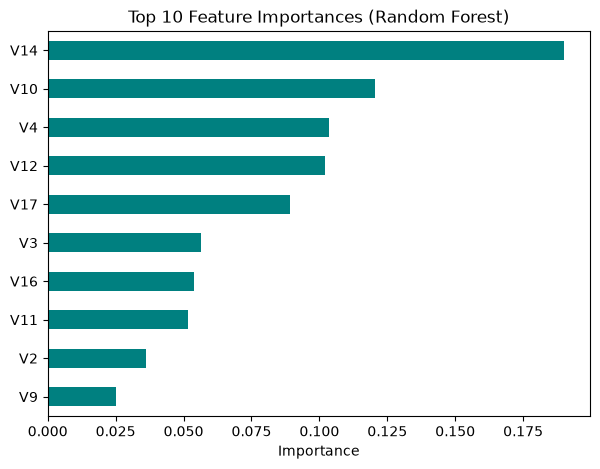

In [24]:
# feature_importances_ tells us how much each column helped the Random Forest decide
importances = pd.Series(rf.feature_importances_, index=X_train.columns)

# Show the 10 most important features as a horizontal bar chart
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(7, 5))
top10.sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.show()

In [25]:
# Save each model to the models folder so we can reuse them without retraining
joblib.dump(log_reg, "../models/log_reg.pkl")
joblib.dump(rf, "../models/random_forest.pkl")
joblib.dump(xgb, "../models/xgboost.pkl")

print("All models saved.")

All models saved.
